<a href="https://colab.research.google.com/github/Maryam-sudo-png/Computer-Vision-Labs/blob/main/Lab_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

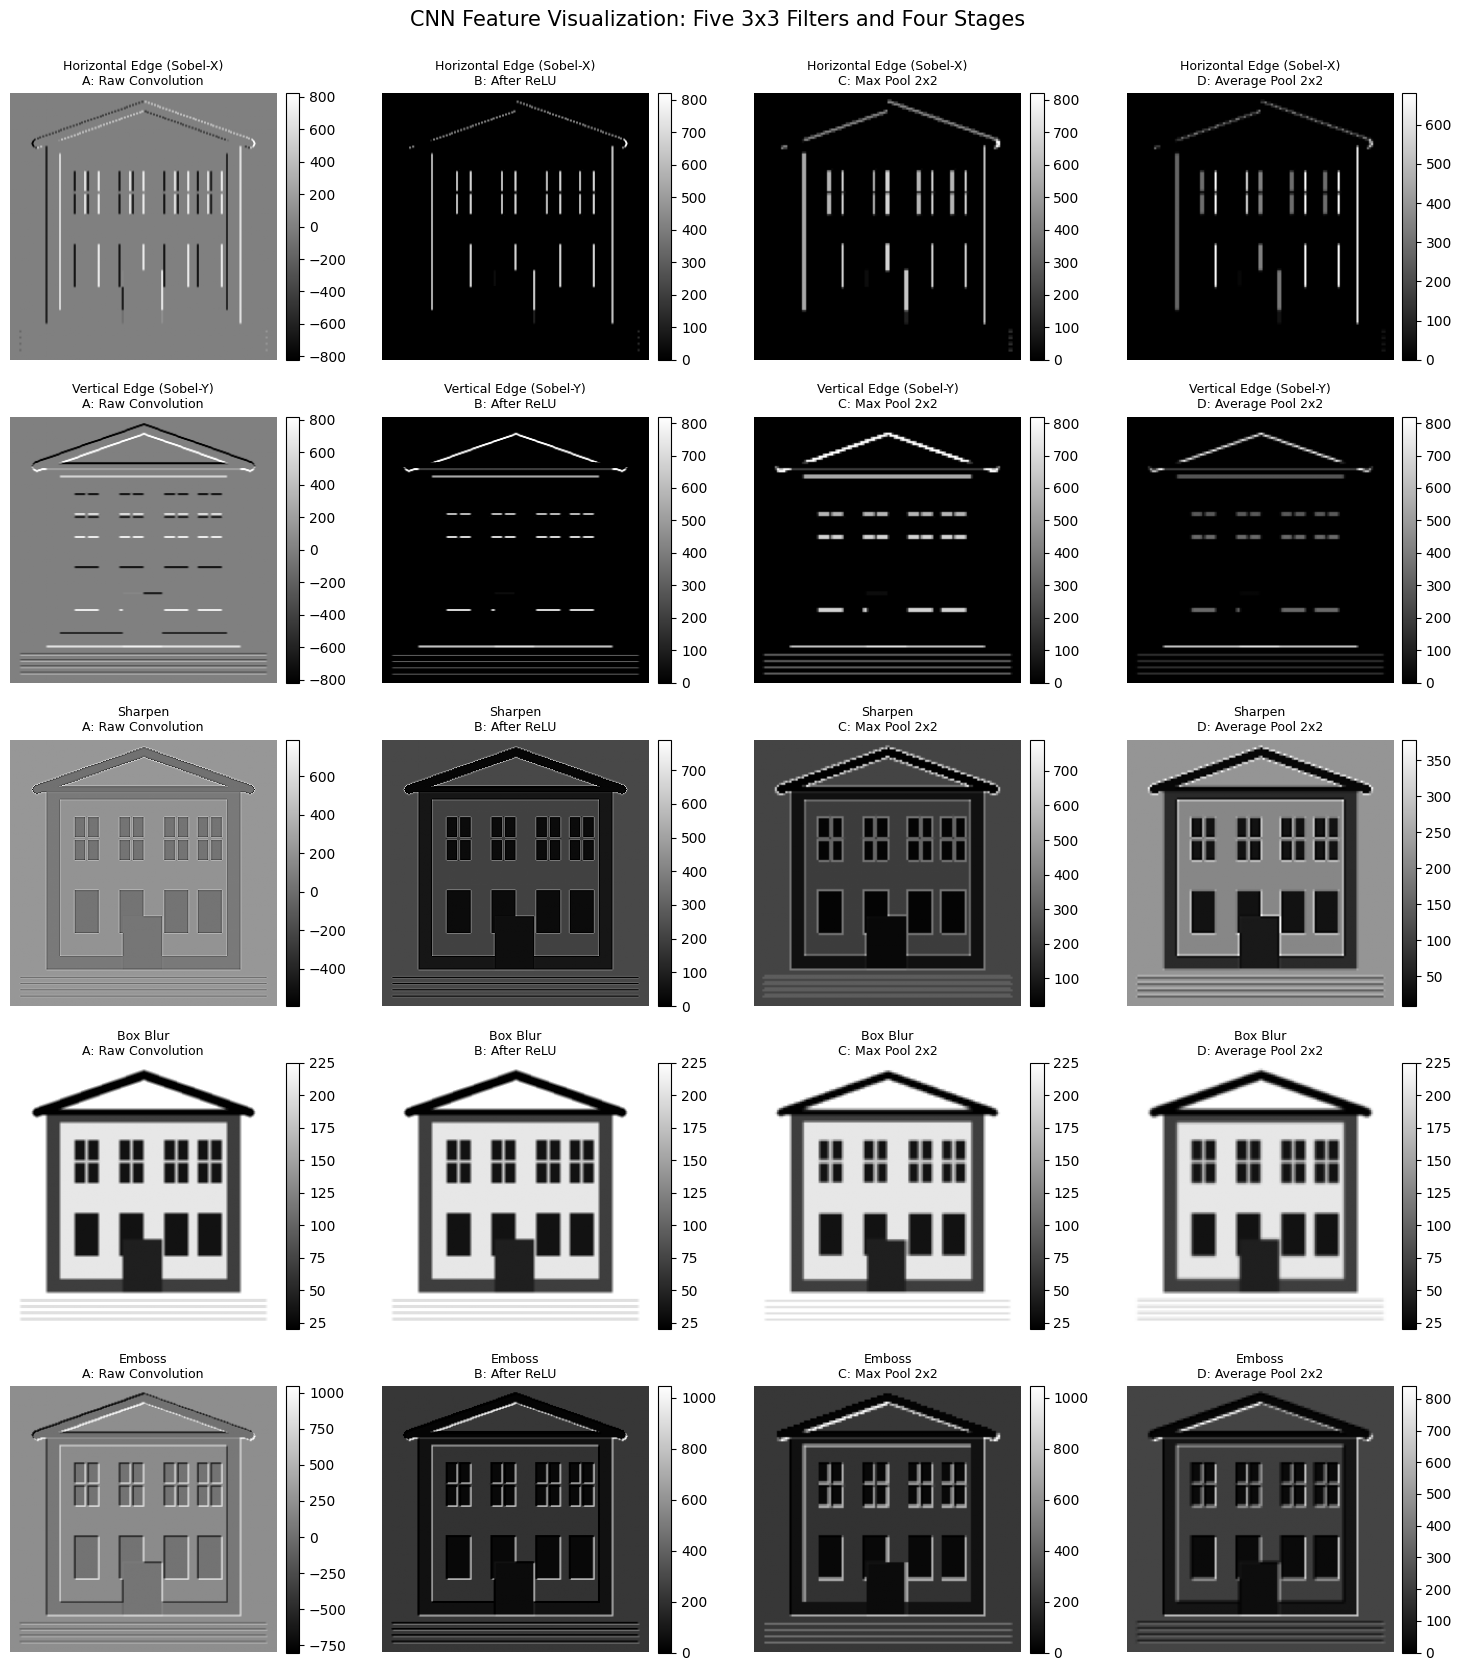

\n========== MODEL A: STANDARD 3x3 + MAX POOLING ==========


Model: "CNN_3x3_max"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool (MaxPooling2D)         │ (None, 16, 16, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_10_classes (Dense)       │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

\nManual expected parameter totals:
Model A: Conv1 140 + Conv2 460 + Dense 110 = 710
Model B: Conv1 380 + Conv2 1260 + Dense 110 = 1750


In [1]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, AveragePooling2D
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense

# ------------------------- PART I: INPUT IMAGE -------------------------
def make_sample_image(size=256):
    """Create a grayscale architectural-style image with edges and textures."""
    img = np.full((size, size), 225, dtype=np.uint8)
    # Main building
    cv2.rectangle(img, (35, 45), (220, 220), 70, thickness=-1)
    cv2.rectangle(img, (48, 58), (207, 207), 205, thickness=-1)
    # Windows
    for x in (62, 105, 148, 180):
        cv2.rectangle(img, (x, 75), (x + 22, 115), 35, thickness=-1)
        cv2.line(img, (x + 11, 75), (x + 11, 115), 180, 2)
        cv2.line(img, (x, 95), (x + 22, 95), 180, 2)
        cv2.rectangle(img, (x, 145), (x + 22, 185), 35, thickness=-1)
    # Roof and structural edges
    pts = np.array([[25, 48], [128, 12], [230, 48]], dtype=np.int32)
    cv2.polylines(img, [pts], False, 20, 7)
    cv2.line(img, (25, 48), (230, 48), 20, 4)
    # Door and ground texture
    cv2.rectangle(img, (108, 170), (145, 220), 45, thickness=-1)
    for y in range(228, 250, 6):
        cv2.line(img, (10, y), (245, y), 150, 1)
    return img

image = make_sample_image()
# Five kernels requested in the assignment
kernels = {
    "Horizontal Edge (Sobel-X)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
    "Vertical Edge (Sobel-Y)":   np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),
    "Sharpen":                   np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32),
    "Box Blur":                  np.ones((3, 3), dtype=np.float32) / 9.0,
    "Emboss":                    np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=np.float32),
}

def pool2x2(feature_map, mode="max"):
    """2x2 pooling with stride 2; crop odd trailing row/column if present."""
    h, w = feature_map.shape
    h2, w2 = h - (h % 2), w - (w % 2)
    cropped = feature_map[:h2, :w2]
    blocks = cropped.reshape(h2 // 2, 2, w2 // 2, 2)
    if mode == "max":
        return blocks.max(axis=(1, 3))
    return blocks.mean(axis=(1, 3))

results = {}
for name, kernel in kernels.items():
    # OpenCV filter2D performs correlation (the common image-filter convention).
    raw = cv2.filter2D(image.astype(np.float32), -1, kernel,
                       borderType=cv2.BORDER_REFLECT)
    relu = np.maximum(raw, 0)
    max_pool = pool2x2(relu, "max")
    avg_pool = pool2x2(relu, "avg")
    results[name] = (raw, relu, max_pool, avg_pool)

# One row per filter; four columns = A, B, C, D
stage_names = ["A: Raw Convolution", "B: After ReLU",
               "C: Max Pool 2x2", "D: Average Pool 2x2"]
fig, axes = plt.subplots(5, 4, figsize=(15, 17))
for r, (name, stage_data) in enumerate(results.items()):
    for c, data in enumerate(stage_data):
        ax = axes[r, c]
        im = ax.imshow(data, cmap="gray")
        ax.set_title(f"{name}\n{stage_names[c]}", fontsize=9)
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle("CNN Feature Visualization: Five 3x3 Filters and Four Stages", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.savefig("cnn_5x4_visualization.png", dpi=200, bbox_inches="tight")
plt.show()

# Save the input image too, for evidence/reporting.
cv2.imwrite("cnn_input_image.png", image)

# ------------------------- PART II: CNN MODELS -------------------------
def build_model(kernel_size, pooling_type):
    """Two conv layers (5 and 10 filters), pooling, GAP, 10-class output."""
    model = Sequential(name=f"CNN_{kernel_size}x{kernel_size}_{pooling_type}")
    model.add(Input(shape=(32, 32, 3)))
    model.add(Conv2D(5, (kernel_size, kernel_size), activation="relu",
                     padding="same", name="conv1"))
    model.add(Conv2D(10, (kernel_size, kernel_size), activation="relu",
                     padding="same", name="conv2"))
    if pooling_type == "max":
        model.add(MaxPooling2D(pool_size=(2, 2), strides=2, name="max_pool"))
    else:
        model.add(AveragePooling2D(pool_size=(2, 2), strides=2, name="avg_pool"))
    model.add(GlobalAveragePooling2D(name="global_average_pooling"))
    model.add(Dense(10, activation="softmax", name="output_10_classes"))
    return model

model_a = build_model(3, "max")
model_b = build_model(5, "avg")

print("\\n========== MODEL A: STANDARD 3x3 + MAX POOLING ==========")
model_a.summary()
print("\\n========== MODEL B: LARGE 5x5 + AVERAGE POOLING ==========")
model_b.summary()

print("\\nManual expected parameter totals:")
print("Model A: Conv1 140 + Conv2 460 + Dense 110 = 710")
print("Model B: Conv1 380 + Conv2 1260 + Dense 110 = 1750")
